# U-Net disease segmentation — save once, reuse anywhere

This notebook saves trained weights, preprocessing settings, training history, test metrics, plots, and predictions in `results/unet_disease_segmentation/`. On later runs it automatically loads the saved model and results. Training and test evaluation stay disabled unless explicitly requested.

**First use:** with the dataset and annotation manifests present, set `RUN_TRAINING = True` in the setup cell and run all cells once. Set `RUN_TEST_EVALUATION = True` to calculate and save held-out test results. Then return both switches to `False` and save the notebook. Existing checkpoints are reused even when the training switch is left on; use a new `OUTPUT` directory for a separate experiment.

**Another device:** copy `unet_disease_segmentation_portable.zip`, extract it, open the included notebook from the extracted folder, and run all cells. Install the packages in the included `requirements.txt` first. The saved history, metrics, and plots can also be viewed directly without Python. The dataset and annotations are unnecessary for loading results or predicting new images. A notebook file alone does not contain the model weights: transfer the ZIP or the notebook together with its `results/unet_disease_segmentation/` folder. Run Jupyter from the extracted folder, or set `ROOT` below to that folder.

A trained epoch-19 checkpoint and saved test results are included in `results/unet_disease_segmentation/`, imported from the training device. Keep both run switches disabled to reuse them without training or repeating evaluation.

The current annotations are automatic draft proposals, not expert reference masks. Saved metrics measure draft-label agreement, not expert-validated segmentation accuracy.

In [1]:
from pathlib import Path
import copy, hashlib, io, json, random, time, zipfile
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd().resolve()
ANNOTATIONS = ROOT / 'results/pixel_annotations_full'
OUTPUT = ROOT / 'results/unet_disease_segmentation'
CONFIG = dict(seed=42, image_size=256, base_channels=32, batch_size=8,
              learning_rate=1e-3, weight_decay=1e-4, max_epochs=50,
              patience=8, min_delta=1e-4, threshold=0.5,
              training_images='augmented', exclude_empty_disease_training_sources=True,
              bce_weight=0.5, label_quality='automatic_draft',
              normalization_mean=[0.5,0.5,0.5], normalization_std=[0.5,0.5,0.5])
# These switches are only needed to produce new results, not to reuse saved ones.
RUN_TRAINING = False
RUN_TEST_EVALUATION = False
CHECKPOINT_PATH = OUTPUT / 'best_model.pt'
saved_checkpoint = None
if CHECKPOINT_PATH.is_file():
    # CPU mapping makes CUDA-trained checkpoints portable to CPU-only devices.
    saved_checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
    if saved_checkpoint.get('architecture') != 'UNet' or saved_checkpoint.get('epoch', 0) < 1:
        raise ValueError('Expected a trained U-Net checkpoint.')
    CONFIG = dict(saved_checkpoint['config'])
    print('Saved model found; using its architecture and preprocessing settings.')

manifest_paths = [ROOT / 'split_dataset/manifest.csv',
                  ANNOTATIONS / 'original_masks_manifest.csv',
                  ANNOTATIONS / 'augmented_masks_manifest.csv']
DATA_AVAILABLE = all(p.is_file() for p in manifest_paths)
# A saved evaluation also remains reusable if its switch was left enabled.
cached_metrics_path = OUTPUT / 'test_metrics.json'
HAS_CACHED_TEST_METRICS = False
if saved_checkpoint is not None and cached_metrics_path.is_file():
    cached = json.loads(cached_metrics_path.read_text(encoding='utf-8'))
    HAS_CACHED_TEST_METRICS = cached.get('checkpoint_sha256') == hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest()
PREPARE_DATA = (RUN_TEST_EVALUATION and not HAS_CACHED_TEST_METRICS) or (RUN_TRAINING and saved_checkpoint is None) or (saved_checkpoint is None and DATA_AVAILABLE)
if PREPARE_DATA and not DATA_AVAILABLE:
    raise FileNotFoundError('Training/evaluation requires the original dataset and annotation manifests. Disable both switches to reuse saved results.')

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])

torch.set_num_threads(4)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(CONFIG['seed'])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Data preparation:', PREPARE_DATA, '| saved checkpoint:', CHECKPOINT_PATH.is_file())

Saved model found; using its architecture and preprocessing settings.
Device: cpu
Data preparation: False | saved checkpoint: True


## Pair images with masks and preserve the split

Use the same original train/validation/test partition as the classification experiments. Training defaults to the existing augmented images and their geometrically matched masks. Set `training_images='original'` to train from original training images instead.

Original disease-labeled training images with entirely empty proposals are excluded by default; all four views of those sources are excluded together. An augmented crop with an empty mask from a nonempty source is still a valid background view. Healthy-class empty masks are retained. Validation/test membership is unchanged, including flagged examples. No validation/test labels are used to build training targets or choose the model architecture.

In [2]:
if PREPARE_DATA:
    split_manifest = pd.read_csv(ROOT / 'split_dataset/manifest.csv')
    original = pd.read_csv(ANNOTATIONS / 'original_masks_manifest.csv')
    augmented = pd.read_csv(ANNOTATIONS / 'augmented_masks_manifest.csv')
    assert original['path'].is_unique and original['source_sha256'].is_unique
    joined = original.merge(split_manifest, on=['split','path'], validate='one_to_one')
    assert len(joined) == len(original) == len(split_manifest)
    assert joined['source_sha256'].eq(joined['sha256']).all()
    assert joined['class_name'].eq(joined['class']).all()
    original['image_path'] = original.apply(lambda r: f"split_dataset/{r['split']}/{r['path']}",axis=1)
    original['sample_id'] = original['id']
    original['source_path'] = original['path']
    original_train = original[original['split']=='train'].copy()
    validation_frame = original[original['split']=='validation'].copy().reset_index(drop=True)
    test_frame = original[original['split']=='test'].copy().reset_index(drop=True)
    source_hash_sets = {s:set(original.loc[original['split']==s,'source_sha256']) for s in ['train','validation','test']}
    assert source_hash_sets['train'].isdisjoint(source_hash_sets['validation'])
    assert source_hash_sets['train'].isdisjoint(source_hash_sets['test'])
    assert source_hash_sets['validation'].isdisjoint(source_hash_sets['test'])

    empty_disease = (original_train['class_name']!='Healthy Rice Leaf') & (original_train['affected_pixels']==0)
    excluded_paths = set(original_train.loc[empty_disease,'path']) if CONFIG['exclude_empty_disease_training_sources'] else set()
    parent = original_train[['path','source_sha256','mask_sha256','class_name']].rename(
        columns={'path':'source_path','source_sha256':'parent_hash',
                 'mask_sha256':'parent_mask_hash','class_name':'parent_class'})
    augmented = augmented.merge(parent,on='source_path',validate='many_to_one')
    assert len(augmented)==11248 and augmented.groupby('source_path').size().eq(4).all()
    assert augmented['source_sha256'].eq(augmented['parent_hash']).all()
    assert augmented['source_mask_sha256'].eq(augmented['parent_mask_hash']).all()
    assert augmented['class_name'].eq(augmented['parent_class']).all()
    assert augmented['split'].eq('train').all()
    augmented['image_path'] = 'augmented_train/' + augmented['path']
    augmented['sample_id'] = [f'aug_{i:05d}' for i in range(len(augmented))]
    if CONFIG['training_images']=='augmented':
        train_frame = augmented[~augmented['source_path'].isin(excluded_paths)].copy()
    elif CONFIG['training_images']=='original':
        train_frame = original_train[~original_train['path'].isin(excluded_paths)].copy()
    else:
        raise ValueError("training_images must be 'original' or 'augmented'")
    train_frame = train_frame.reset_index(drop=True)
    assert set(train_frame['source_sha256']).issubset(source_hash_sets['train'])
    assert set(train_frame['source_sha256']).isdisjoint(source_hash_sets['validation']|source_hash_sets['test'])
    summary = pd.DataFrame([dict(split='train',images=len(train_frame),sources=train_frame['source_sha256'].nunique()),
                            dict(split='validation',images=len(validation_frame),sources=len(validation_frame)),
                            dict(split='test',images=len(test_frame),sources=len(test_frame))])
    display(summary)
    print('Excluded empty disease-labeled training sources:',len(excluded_paths))
    print('All annotation targets remain draft labels; split membership is unchanged.')
else:
    print('Dataset loading skipped; saved-model reuse does not need the training data.')

Dataset loading skipped; saved-model reuse does not need the training data.


## Aligned image and target loading

Images are EXIF-corrected in the same way as the annotations. Preserve aspect ratio by resizing and padding to a square. RGB uses bilinear sampling; masks use nearest-neighbor. A validity mask excludes padded pixels from loss and metrics. Targets remain binary 0/1.

At 256 pixels, very small lesions can disappear during resizing. This is tracked in the dataset output. Increase `image_size` if needed for small-spot detail. No additional random geometry is applied independently to an image or mask.

In [3]:
def letterbox_pair(image, mask, size):
    width,height = image.size
    if mask.shape != (height,width):
        raise ValueError('Image and mask have different native dimensions')
    scale = min(size/width,size/height)
    nw,nh = max(1,round(width*scale)),max(1,round(height*scale))
    left,top = (size-nw)//2,(size-nh)//2
    resized = np.asarray(image.resize((nw,nh),Image.Resampling.BILINEAR))
    target = np.asarray(Image.fromarray(mask).resize((nw,nh),Image.Resampling.NEAREST))
    rgb = np.zeros((size,size,3),dtype=np.uint8)
    y = np.zeros((size,size),dtype=np.uint8)
    valid = np.zeros((size,size),dtype=np.float32)
    rgb[top:top+nh,left:left+nw] = resized
    y[top:top+nh,left:left+nw] = target
    valid[top:top+nh,left:left+nw] = 1
    x = torch.from_numpy(rgb.copy()).permute(2,0,1).float()/255
    mean = torch.tensor(CONFIG['normalization_mean'])[:,None,None]
    std = torch.tensor(CONFIG['normalization_std'])[:,None,None]
    return (x-mean)/std,torch.from_numpy(y.copy()).float()[None],torch.from_numpy(valid)[None]

class RiceLesionDataset(Dataset):
    def __init__(self,frame,size):
        self.rows = frame.to_dict('records')
        self.size = size
    def __len__(self):
        return len(self.rows)
    def __getitem__(self,index):
        row = self.rows[index]
        with Image.open(ROOT/row['image_path']) as im:
            image = ImageOps.exif_transpose(im).convert('RGB')
        with Image.open(ROOT/row['mask_path']) as im:
            mask = np.array(im)
        if mask.ndim != 2 or not np.isin(mask,[0,1]).all():
            raise ValueError(f"Expected a binary mask: {row['mask_path']}")
        native_positive = bool(mask.any())
        x,y,valid = letterbox_pair(image,mask,self.size)
        return dict(image=x,target=y,valid=valid,sample_id=row['sample_id'],
                    source_sha256=row['source_sha256'],class_name=row['class_name'],
                    native_positive=native_positive,
                    lost_small_lesion=bool(native_positive and not y.any()))

if PREPARE_DATA:
    train_data = RiceLesionDataset(train_frame,CONFIG['image_size'])
    validation_data = RiceLesionDataset(validation_frame,CONFIG['image_size'])
    test_data = RiceLesionDataset(test_frame,CONFIG['image_size'])
    # num_workers=0 keeps Windows/Jupyter execution independent of worker pickling.
    train_loader = DataLoader(train_data,batch_size=CONFIG['batch_size'],shuffle=True,num_workers=0,
                              generator=torch.Generator().manual_seed(CONFIG['seed']),pin_memory=DEVICE.type=='cuda')
    validation_loader = DataLoader(validation_data,batch_size=CONFIG['batch_size'],shuffle=False,num_workers=0)
    test_loader = DataLoader(test_data,batch_size=CONFIG['batch_size'],shuffle=False,num_workers=0)
    print('Data loaders prepared. No training batches have been optimized.')
else:
    print('Data loaders skipped. Inference helpers remain available.')

Data loaders skipped. Inference helpers remain available.


## Inspect the training targets

These are source images and annotation drafts, not predictions from the untrained U-Net. Black padding is ignored by the loss. A healthy example is included as a negative control.

In [4]:
if PREPARE_DATA:
    healthy_index = int(np.flatnonzero(test_frame['class_name'].eq('Healthy Rice Leaf').to_numpy())[0])
    examples = [('Train',train_data[0]),('Validation',validation_data[0]),
                ('Test',test_data[0]),('Healthy test control',test_data[healthy_index])]
    fig = Figure(figsize=(11,12),layout='constrained'); FigureCanvasAgg(fig)
    axes = fig.subplots(len(examples),3)
    for row_axes,(label,sample) in zip(axes,examples):
        rgb = sample['image'].permute(1,2,0).numpy()*np.array(CONFIG['normalization_std'])+np.array(CONFIG['normalization_mean'])
        rgb = np.clip(rgb,0,1)
        mask = sample['target'][0].numpy().astype(bool)
        marked = rgb.copy();marked[mask] = marked[mask]*0.55 + np.array([1,0.1,0.15])*0.45
        for ax,picture,title in zip(row_axes,[rgb,mask,marked],
                [label+' / '+sample['class_name'],'Draft disease mask','Aligned draft overlay']):
            ax.imshow(picture,cmap='gray',vmin=0,vmax=1);ax.set_title(title,fontsize=9);ax.axis('off')
    fig.suptitle('U-Net inputs and draft targets - no model predictions')
    buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=120);display(DisplayImage(data=buffer.getvalue()))
else:
    print('Draft-target preview skipped; no dataset is needed to reload results.')

Draft-target preview skipped; no dataset is needed to reload results.


## U-Net architecture

A compact U-Net trained from scratch: four downsampling blocks, a bottleneck, four transposed-convolution upsampling blocks, and encoder-to-decoder skip connections. Each block has two 3 x 3 convolutions with batch normalization and ReLU. The final 1 x 1 convolution emits one logit per pixel. Sigmoid is applied only for probabilities/metrics, because the loss uses logits.

In [5]:
class DoubleConv(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True),
            nn.Conv2d(out_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True))
    def forward(self,x):
        return self.layers(x)

class Down(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.layers = nn.Sequential(nn.MaxPool2d(2),DoubleConv(in_channels,out_channels))
    def forward(self,x):
        return self.layers(x)

class Up(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels,in_channels//2,kernel_size=2,stride=2)
        self.conv = DoubleConv(in_channels,out_channels)
    def forward(self,x,skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = F.interpolate(x,size=skip.shape[-2:],mode='bilinear',align_corners=False)
        return self.conv(torch.cat([skip,x],dim=1))

class UNet(nn.Module):
    def __init__(self,in_channels=3,out_channels=1,base_channels=32):
        super().__init__()
        b = base_channels
        self.input = DoubleConv(in_channels,b)
        self.down1 = Down(b,b*2);self.down2 = Down(b*2,b*4)
        self.down3 = Down(b*4,b*8);self.bottleneck = Down(b*8,b*16)
        self.up1 = Up(b*16,b*8);self.up2 = Up(b*8,b*4)
        self.up3 = Up(b*4,b*2);self.up4 = Up(b*2,b)
        self.output = nn.Conv2d(b,out_channels,kernel_size=1)
    def forward(self,x):
        a = self.input(x);b = self.down1(a);c = self.down2(b);d = self.down3(c)
        x = self.bottleneck(d)
        x = self.up1(x,d);x = self.up2(x,c);x = self.up3(x,b);x = self.up4(x,a)
        return self.output(x)

model = UNet(base_channels=CONFIG['base_channels']).to(DEVICE)
MODEL_TRAINED = saved_checkpoint is not None
if MODEL_TRAINED:
    model.load_state_dict(saved_checkpoint['model_state_dict'])
    model.eval()
    print(f"Loaded trained U-Net from epoch {saved_checkpoint['epoch']}; ready for prediction.")
else:
    print('Random initialization only. Enable RUN_TRAINING once to create reusable weights.')
parameters = sum(p.numel() for p in model.parameters())
print(f'Parameters: {parameters:,}; output channels: 1')

Loaded trained U-Net from epoch 19; ready for prediction.
Parameters: 7,763,041; output channels: 1


## Loss and segmentation metrics

Use equally weighted binary cross-entropy with logits and soft Dice loss. Padding is excluded from both. Report foreground Dice/IoU and precision/recall. Also report Dice/IoU averaged over images with positive targets, so healthy empty masks cannot dominate the headline.

For an empty target and empty prediction, per-image Dice/IoU is 1. The number of empty targets and lesions lost during downsampling is reported explicitly. A score against these draft targets measures draft-label agreement; it is not expert-validated performance.

In [6]:
class BCEDiceLoss(nn.Module):
    def __init__(self,bce_weight=0.5):
        super().__init__();self.bce_weight=bce_weight
    def forward(self,logits,target,valid):
        target=target.float();valid=valid.float()
        bce=F.binary_cross_entropy_with_logits(logits,target,reduction='none')
        bce=(bce*valid).sum()/valid.sum().clamp_min(1)
        probabilities=logits.sigmoid()*valid
        truth=target*valid
        intersection=(probabilities*truth).sum(dim=(1,2,3))
        denominator=probabilities.sum(dim=(1,2,3))+truth.sum(dim=(1,2,3))
        dice=(2*intersection+1)/(denominator+1)
        return self.bce_weight*bce+(1-self.bce_weight)*(1-dice).mean()

criterion=BCEDiceLoss(CONFIG['bce_weight'])

class SegmentationMeter:
    def __init__(self,threshold=0.5):
        self.threshold=threshold;self.tp=0;self.fp=0;self.fn=0
        self.dice=[];self.iou=[];self.positive_dice=[];self.positive_iou=[]
        self.empty_targets=0;self.lost_small_lesions=0
    def update(self,logits,target,valid,lost_small_lesion=None):
        prediction=(logits.sigmoid()>=self.threshold)&valid.bool()
        truth=target.bool()&valid.bool()
        dims=(1,2,3)
        tp=(prediction&truth).sum(dims).detach().cpu().numpy()
        fp=(prediction&~truth).sum(dims).detach().cpu().numpy()
        fn=(~prediction&truth).sum(dims).detach().cpu().numpy()
        self.tp+=int(tp.sum());self.fp+=int(fp.sum());self.fn+=int(fn.sum())
        for a,b,c in zip(tp,fp,fn):
            d=float(2*a/(2*a+b+c)) if 2*a+b+c else 1.0
            j=float(a/(a+b+c)) if a+b+c else 1.0
            self.dice.append(d);self.iou.append(j)
            if a+c:self.positive_dice.append(d);self.positive_iou.append(j)
            else:self.empty_targets+=1
        if lost_small_lesion is not None:self.lost_small_lesions+=int(torch.as_tensor(lost_small_lesion).sum())
    def compute(self):
        def ratio(n,d,empty=1.0):return float(n/d) if d else empty
        return dict(dice=ratio(2*self.tp,2*self.tp+self.fp+self.fn),iou=ratio(self.tp,self.tp+self.fp+self.fn),
            precision=ratio(self.tp,self.tp+self.fp,empty=1.0 if self.tp+self.fn==0 else 0.0),recall=ratio(self.tp,self.tp+self.fn,empty=1.0 if self.tp+self.fp==0 else 0.0),
            mean_image_dice=float(np.mean(self.dice)) if self.dice else None,
            mean_positive_image_dice=float(np.mean(self.positive_dice)) if self.positive_dice else None,
            mean_positive_image_iou=float(np.mean(self.positive_iou)) if self.positive_iou else None,
            images=len(self.dice),positive_target_images=len(self.positive_dice),empty_target_images=self.empty_targets,
            small_lesions_lost_on_resize=self.lost_small_lesions)

@torch.inference_mode()
def evaluate_unet(model,loader,criterion,device):
    model.eval();meter=SegmentationMeter(CONFIG['threshold']);total_loss=0.;images=0
    for batch in loader:
        x=batch['image'].to(device);y=batch['target'].to(device);valid=batch['valid'].to(device)
        logits=model(x);loss=criterion(logits,y,valid)
        total_loss+=float(loss)*len(x);images+=len(x)
        meter.update(logits,y,valid,batch['lost_small_lesion'])
    if not images:raise ValueError('Empty evaluation loader')
    metrics=meter.compute();metrics['loss']=total_loss/images
    return metrics

## Forward-pass checks only

The following checks do not train the model. They verify output sizes, loss finiteness, padding-aware metrics, and that every model parameter and buffer remains unchanged. No untrained segmentation predictions are presented as results.

In [7]:
def state_fingerprint(module):
    digest=hashlib.sha256()
    for name,tensor in module.state_dict().items():
        digest.update(name.encode());digest.update(tensor.detach().cpu().numpy().tobytes())
    return digest.hexdigest()

model.eval()
before=state_fingerprint(model)
check_samples = ([train_data[0], train_data[1]] if PREPARE_DATA else
                 [dict(image=torch.zeros(3, CONFIG['image_size'], CONFIG['image_size']),
                       target=torch.zeros(1, CONFIG['image_size'], CONFIG['image_size']),
                       valid=torch.ones(1, CONFIG['image_size'], CONFIG['image_size'])) for _ in range(2)])
check_batch={key:torch.stack([s[key] for s in check_samples]) for key in ['image','target','valid']}
with torch.inference_mode():
    x=check_batch['image'][:2].to(DEVICE)
    y=check_batch['target'][:2].to(DEVICE);valid=check_batch['valid'][:2].to(DEVICE)
    logits=model(x)
    assert logits.shape==(len(x),1,CONFIG['image_size'],CONFIG['image_size'])
    assert torch.isfinite(criterion(logits,y,valid))
    assert model(torch.zeros(1,3,65,79,device=DEVICE)).shape==(1,1,65,79)
assert state_fingerprint(model)==before
assert all(p.grad is None for p in model.parameters())
# Perfect synthetic predictions, including ignored padding and a healthy empty mask.
truth=torch.zeros(2,1,8,8);truth[0,0,2:4,2:4]=1
valid=torch.ones_like(truth);valid[:,:,:,0]=0
perfect=torch.where(truth.bool(),torch.tensor(20.),torch.tensor(-20.))
perfect[:,:,:,0]=20.  # These invalid pixels must not count as false positives.
meter=SegmentationMeter();meter.update(perfect,truth,valid)
assert meter.compute()['dice']==1 and meter.compute()['iou']==1
assert meter.compute()['positive_target_images']==1 and meter.compute()['empty_target_images']==1
wrong=-perfect;meter=SegmentationMeter();meter.update(wrong,truth,valid)
assert meter.compute()['dice']==0 and meter.compute()['iou']==0
print('Forward checks passed:',tuple(logits.shape))
print('Weights and batch-normalization buffers unchanged. No gradients or optimizer steps were produced.')

Forward checks passed: (2, 1, 256, 256)
Weights and batch-normalization buffers unchanged. No gradients or optimizer steps were produced.


## Train once and persist the best model

`RUN_TRAINING` creates a new run only when no trained checkpoint exists. Each completed epoch saves `last_checkpoint.pt` and `history.csv`; improved validation loss saves `best_model.pt`. The checkpoint stores model tensors and configuration rather than a pickled notebook class, so the architecture can be rebuilt on another device. The best validation checkpoint is loaded after training. Test data is never used for model selection.

Existing results are protected. A partial run with only a last checkpoint/history requires a different `OUTPUT` directory before starting a new experiment. Training is not automatically resumed.

In [8]:
def fit_unet(model,train_loader,validation_loader,device,config):
    OUTPUT.mkdir(parents=True,exist_ok=True)
    if any((OUTPUT/name).exists() for name in ['best_model.pt', 'last_checkpoint.pt', 'history.csv']):
        raise FileExistsError('Existing U-Net results found. Select a new OUTPUT directory to start another run.')
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['learning_rate'],weight_decay=config['weight_decay'])
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=2)
    scaler=torch.amp.GradScaler('cuda',enabled=device.type=='cuda')
    loss_function=BCEDiceLoss(config['bce_weight'])
    best_loss=float('inf');wait=0;history=[]
    provenance={name:hashlib.sha256(path.read_bytes()).hexdigest() for name,path in {
        'split_manifest':ROOT/'split_dataset/manifest.csv',
        'original_masks_manifest':ANNOTATIONS/'original_masks_manifest.csv',
        'augmented_masks_manifest':ANNOTATIONS/'augmented_masks_manifest.csv'}.items()}
    for epoch in range(1,config['max_epochs']+1):
        started=time.perf_counter();model.train();total_loss=0.;seen=0
        for batch in train_loader:
            x=batch['image'].to(device);y=batch['target'].to(device);valid=batch['valid'].to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type,enabled=device.type=='cuda'):
                logits=model(x);loss=loss_function(logits,y,valid)
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite training loss')
            scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
            total_loss+=float(loss.detach())*len(x);seen+=len(x)
        validation=evaluate_unet(model,validation_loader,loss_function,device)
        scheduler.step(validation['loss'])
        improved=validation['loss']<best_loss-config['min_delta']
        if improved:best_loss=validation['loss'];wait=0
        else:wait+=1
        history.append(dict(epoch=epoch,train_loss=total_loss/seen,validation_loss=validation['loss'],
            validation_dice=validation['dice'],validation_iou=validation['iou'],
            validation_positive_image_dice=validation['mean_positive_image_dice'],
            learning_rate=optimizer.param_groups[0]['lr'],seconds=time.perf_counter()-started))
        checkpoint=dict(epoch=epoch,architecture='UNet',in_channels=3,out_channels=1,
            config=dict(config),model_state_dict={name: value.detach().cpu().clone() for name, value in model.state_dict().items()},optimizer_state_dict=optimizer.state_dict(),
            best_validation_loss=best_loss,manifest_sha256=provenance,
            excluded_empty_training_sources=len(excluded_paths),torch_version=str(torch.__version__),
            labels_are_expert_ground_truth=False,validation_metrics=validation)
        torch.save(checkpoint,OUTPUT/'last_checkpoint.pt')
        if improved:torch.save(checkpoint,OUTPUT/'best_model.pt')
        pd.DataFrame(history).to_csv(OUTPUT/'history.csv',index=False)
        print(f"Epoch {epoch}: train loss={total_loss/seen:.4f}; validation loss={validation['loss']:.4f}; Dice={validation['dice']:.4f}")
        if wait>=config['patience']:
            print('Early stopping');break
    best=torch.load(OUTPUT/'best_model.pt',map_location=device,weights_only=True)
    model.load_state_dict(best['model_state_dict']);model.eval()
    return pd.DataFrame(history)

In [9]:
if MODEL_TRAINED:
    print('Saved trained model reused; training skipped.')
elif RUN_TRAINING:
    training_history = fit_unet(model, train_loader, validation_loader, DEVICE, CONFIG)
    saved_checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
    MODEL_TRAINED = True
    display(training_history)
else:
    print('Training disabled. No trained weights exist yet; enable RUN_TRAINING once.')
if (OUTPUT / 'history.csv').is_file():
    training_history = pd.read_csv(OUTPUT / 'history.csv')
    display(training_history)

Saved trained model reused; training skipped.


,epoch,train_loss,validation_loss,validation_dice,validation_iou,validation_positive_image_dice,learning_rate,seconds
0,1,0.368955,0.296413,0.755809,0.607471,0.646947,0.0010,453.975778
1,2,0.288636,0.259589,0.757273,0.609364,0.640826,0.0010,234.370990
2,3,0.267760,0.251895,0.760442,0.613479,0.645299,0.0010,220.383736
3,4,0.254544,0.242627,0.765442,0.620013,0.660477,0.0010,220.510426
4,5,0.253605,0.240324,0.777309,0.635737,0.663859,0.0010,220.544050
5,6,0.248506,0.232578,0.780738,0.640336,0.671249,0.0010,218.536547
6,7,0.236145,0.236995,0.769207,0.624969,0.673066,0.0010,220.743367
7,8,0.236250,0.245138,0.760566,0.613639,0.656750,0.0010,219.948694
8,9,0.232865,0.223535,0.782281,0.642415,0.685308,0.0010,219.060861
9,10,0.233214,0.223788,0.780356,0.639823,0.693761,0.0010,218.786714


## Save test results once, then reload them

Existing `test_metrics.json` is displayed automatically. The test loader is only evaluated when `RUN_TEST_EVALUATION = True` and no matching saved result exists. A checkpoint SHA-256 binds newly saved metrics to the exact selected model. The original annotation/split hashes are checked before a new test evaluation. Legacy results without a checkpoint hash can be viewed but are explicitly marked as unverified.

In [10]:
metrics_path = OUTPUT / 'test_metrics.json'
checkpoint_hash = hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest() if MODEL_TRAINED else None
test_metrics = None
if metrics_path.is_file():
    cached_metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
    if checkpoint_hash and cached_metrics.get('checkpoint_sha256') == checkpoint_hash:
        test_metrics = cached_metrics
        print('Loaded saved test results; no evaluation was repeated.')
    elif 'checkpoint_sha256' not in cached_metrics:
        print('Legacy saved test results (model identity unverified):')
        display(cached_metrics)
    else:
        print('Saved test results belong to a different model; they are not reused.')
if RUN_TEST_EVALUATION and test_metrics is None:
    if not MODEL_TRAINED:
        raise FileNotFoundError('Train a U-Net checkpoint before test evaluation.')
    for name, manifest in zip(['split_manifest', 'original_masks_manifest', 'augmented_masks_manifest'], manifest_paths):
        if saved_checkpoint['manifest_sha256'][name] != hashlib.sha256(manifest.read_bytes()).hexdigest():
            raise ValueError(f'Annotation/split provenance changed: {name}')
    test_metrics = evaluate_unet(model, test_loader, BCEDiceLoss(CONFIG['bce_weight']), DEVICE)
    test_metrics.update(label_quality=CONFIG['label_quality'],
                        interpretation='draft-label agreement, not expert-reference accuracy',
                        checkpoint_sha256=checkpoint_hash, checkpoint_epoch=saved_checkpoint['epoch'])
    metrics_path.write_text(json.dumps(test_metrics, indent=2, allow_nan=False), encoding='utf-8')
if test_metrics is not None:
    display(pd.DataFrame([test_metrics]))
elif not RUN_TEST_EVALUATION:
    print('No verified test metrics saved yet. Enable RUN_TEST_EVALUATION once with the original data.')

Loaded saved test results; no evaluation was repeated.


,dice,iou,precision,recall,mean_image_dice,mean_positive_image_dice,mean_positive_image_iou,images,positive_target_images,empty_target_images,small_lesions_lost_on_resize,loss,label_quality,interpretation,checkpoint_sha256,checkpoint_epoch,gpu_device,vram_gb
0,0.806438,0.675656,0.78065,0.833988,0.725868,0.719425,0.609398,584,510,74,0,0.196882,automatic_draft,"draft-label agreement, not expert-reference ac...",6975b39b5a979e3a72bd194acfa2baa3603e1f2823c073...,19,cuda,4.0


## Predict new images without the original dataset

After a saved checkpoint has loaded, call `predict_image('path/to/leaf.jpg')`. This uses the saved normalization, input size, and threshold. The mask and probability map are restored to the EXIF-corrected image's native dimensions. A binary PNG, probability array, overlay PNG, and metadata JSON are saved under `predictions/`; supply a different `name` to keep separate predictions. The mask uses 0 for background and 255 for disease. Predictions also remain drafts, not diagnoses.

The cell only defines the helper; it does not require or invent a sample image. Call `export_portable_bundle()` again after creating predictions to include them in the ZIP.

In [11]:
@torch.inference_mode()
def predict_image(image_path, name=None):
    if not MODEL_TRAINED:
        raise RuntimeError('Load or train a saved U-Net before predicting; random weights are not usable results.')
    image_path = Path(image_path)
    with Image.open(image_path) as im:
        image = ImageOps.exif_transpose(im).convert('RGB')
    width, height = image.size
    size = CONFIG['image_size']
    x, _, _ = letterbox_pair(image, np.zeros((height, width), dtype=np.uint8), size)
    model.eval()
    probability = model(x[None].to(DEVICE)).sigmoid()[0, 0].cpu().numpy()
    scale = min(size / width, size / height)
    nw, nh = max(1, round(width * scale)), max(1, round(height * scale))
    left, top = (size - nw) // 2, (size - nh) // 2
    probability = np.array(Image.fromarray(probability[top:top+nh, left:left+nw]).resize(
        (width, height), Image.Resampling.BILINEAR))
    mask = probability >= CONFIG['threshold']
    overlay = np.array(image).copy()
    overlay[mask] = (overlay[mask] * 0.55 + np.array([255, 25, 38]) * 0.45).astype(np.uint8)
    prediction_dir = OUTPUT / 'predictions'
    prediction_dir.mkdir(parents=True, exist_ok=True)
    stem = Path(name or image_path.stem).name
    if stem in ('', '.', '..'):
        raise ValueError('Use a nonempty prediction name.')
    Image.fromarray(mask.astype(np.uint8) * 255).save(prediction_dir / f'{stem}_mask.png')
    Image.fromarray(overlay).save(prediction_dir / f'{stem}_overlay.png')
    np.save(prediction_dir / f'{stem}_probabilities.npy', probability)
    metadata = dict(source_image_name=image_path.name, width=width, height=height,
                    threshold=CONFIG['threshold'], affected_pixel_fraction=float(mask.mean()),
                    checkpoint_sha256=hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest(),
                    label_quality=CONFIG['label_quality'])
    (prediction_dir / f'{stem}_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    display(DisplayImage(data=(prediction_dir / f'{stem}_overlay.png').read_bytes()))
    return dict(mask=mask, probabilities=probability, metadata=metadata)

# Example after loading a trained checkpoint:
# prediction = predict_image('my_leaf.jpg')

## Saved plots and a portable ZIP

The following cell saves a history plot and exports the notebook plus all files in this run's results folder, including weights, history, test metrics when available, and predictions. It also writes package versions and a usage guide. It does not bundle the dataset. The ZIP is regenerated when this cell is run with a trained model; exporting does not train or evaluate anything. Keep a backup of the ZIP outside this computer.

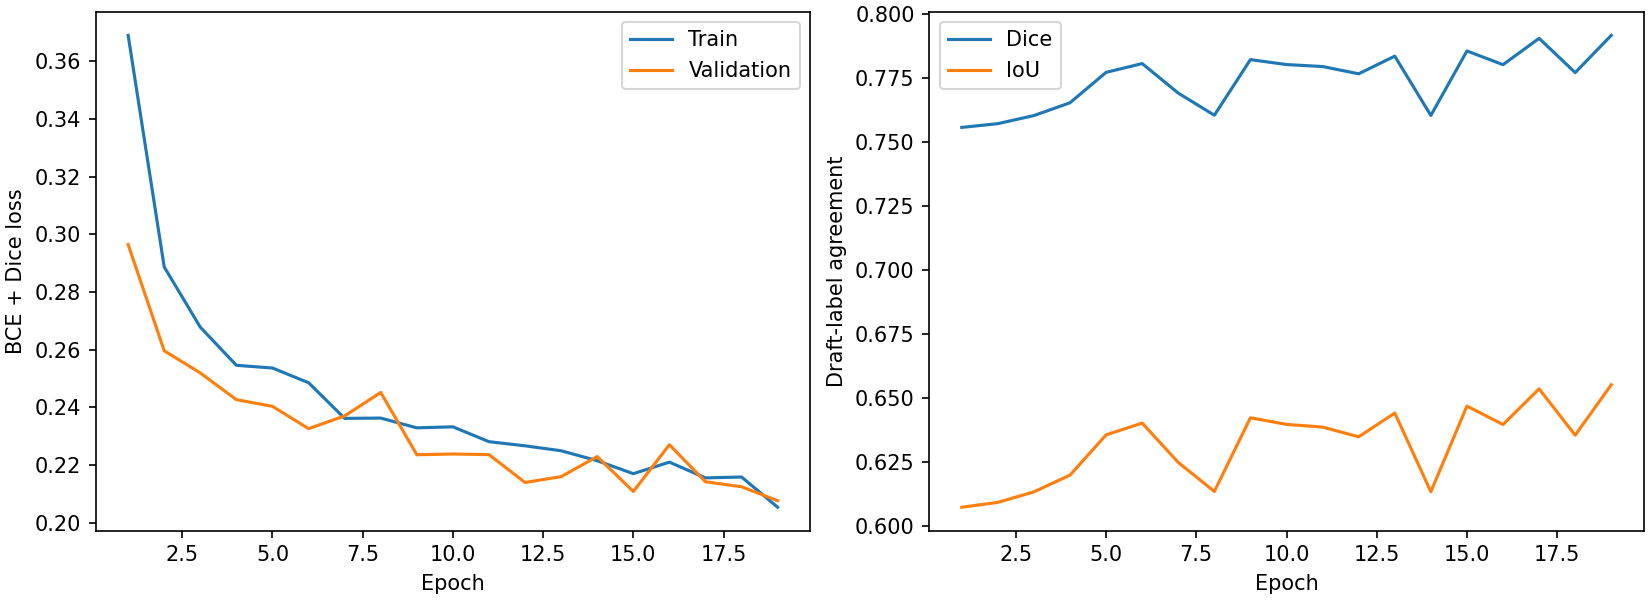

Portable model and results bundle: C:\paras\Final-Year-Project\Final-Year-Project\unet_disease_segmentation_portable.zip


In [12]:
def export_portable_bundle():
    if not MODEL_TRAINED or not CHECKPOINT_PATH.is_file():
        raise RuntimeError('Train once before exporting a reusable model bundle.')
    OUTPUT.mkdir(parents=True, exist_ok=True)
    (OUTPUT / 'config.json').write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')
    # Exact versions document the working environment; choose the appropriate PyTorch build for your device.
    from importlib.metadata import version
    packages = ['torch', 'numpy', 'pandas', 'Pillow', 'matplotlib', 'ipython']
    requirements = '\n'.join(f'{package}=={version(package)}' for package in packages) + '\njupyterlab\n'
    (OUTPUT / 'requirements.txt').write_text(requirements, encoding='utf-8')
    notebook_path = ROOT / 'unet_disease_segmentation.ipynb'
    if not notebook_path.is_file():
        raise FileNotFoundError('Save this notebook as unet_disease_segmentation.ipynb in ROOT before exporting.')
    (OUTPUT / 'README.txt').write_text(
        'Extract the entire ZIP. Install requirements.txt (use a compatible PyTorch build for your OS).\n'
        'Start Jupyter in the extracted folder and open unet_disease_segmentation.ipynb.\n'
        'Keep RUN_TRAINING=False and RUN_TEST_EVALUATION=False; run all cells.\n'
        'The trained model, history and saved metrics load without the dataset or retraining.\n'
        'Call predict_image(path) for a new image; export_portable_bundle() refreshes this ZIP.\n'
        'Missing test_metrics.json means held-out evaluation has not been saved yet.\n'
        'Only load model bundles from a trusted source. Labels are automatic drafts.\n', encoding='utf-8')
    bundle = ROOT / 'unet_disease_segmentation_portable.zip'
    temporary = bundle.with_suffix('.zip.tmp')
    with zipfile.ZipFile(temporary, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
        archive.write(notebook_path, notebook_path.name)
        for file in sorted(OUTPUT.rglob('*')):
            if file.is_file():
                archive.write(file, Path('results/unet_disease_segmentation') / file.relative_to(OUTPUT))
        archive.write(OUTPUT / 'requirements.txt', 'requirements.txt')
        archive.write(OUTPUT / 'README.txt', 'README.txt')
    temporary.replace(bundle)
    print('Portable model and results bundle:', bundle)
    return bundle

if MODEL_TRAINED:
    history_path = OUTPUT / 'history.csv'
    if history_path.is_file():
        history = pd.read_csv(history_path)
        fig = Figure(figsize=(11, 4), layout='constrained'); FigureCanvasAgg(fig)
        loss_ax, score_ax = fig.subplots(1, 2)
        loss_ax.plot(history['epoch'], history['train_loss'], label='Train')
        loss_ax.plot(history['epoch'], history['validation_loss'], label='Validation')
        loss_ax.set(xlabel='Epoch', ylabel='BCE + Dice loss'); loss_ax.legend()
        score_ax.plot(history['epoch'], history['validation_dice'], label='Dice')
        score_ax.plot(history['epoch'], history['validation_iou'], label='IoU')
        score_ax.set(xlabel='Epoch', ylabel='Draft-label agreement'); score_ax.legend()
        fig.savefig(OUTPUT / 'training_history.png', dpi=150)
        display(DisplayImage(data=(OUTPUT / 'training_history.png').read_bytes()))
    export_portable_bundle()
else:
    print('No trained weights to export yet. Enable training once; later runs will reuse the saved results.')